# Nhiệm vụ 3: Học có giám sát - Pipeline Hồi quy (Regression)
Dữ liệu: lịch chiếu phim CGV (`cgv_eda_cleaned.csv`).

- **Đặc trưng mục tiêu:** số suất chiếu của một phim tại một rạp trong một ngày (`NumShowings`).
- **Thuật toán:** `LinearRegression()` và `DecisionTreeRegressor()`.
- **Đánh giá:** `train_test_split`, MSE, RMSE, R².
- **Đầu ra chẩn đoán:** Actual vs Predicted và Residual Plot.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

CSV_PATH = "cgv_eda_cleaned.csv"
RANDOM_STATE = 42

df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ShowDate"] = pd.to_datetime(df["ShowDate"])
df["ReleaseDate"] = pd.to_datetime(df["ReleaseDate"])
print("Dữ liệu gốc:", df.shape)

## 1. Tạo đặc trưng mục tiêu
Dữ liệu chỉ có lịch chiếu, không có doanh thu hay giá vé, và `DurationMinutes` chỉ có 14 giá trị (mỗi phim một giá trị) nên không phù hợp làm target. Vì vậy gộp theo phim × rạp × ngày và đếm số suất chiếu.

In [ ]:
agg = (
    df.groupby(["MovieName", "Cinema", "ShowDate"])
      .agg(NumShowings=("ShowTime", "count"),
           Rating=("Rating", "first"),
           Genre=("Genre", "first"),
           DurationMinutes=("DurationMinutes", "first"),
           ReleaseDate=("ReleaseDate", "first"))
      .reset_index()
)

agg["Rating"] = agg["Rating"].str.upper()
agg["DayOfWeek"] = agg["ShowDate"].dt.dayofweek
agg["IsWeekend"] = (agg["DayOfWeek"] >= 5).astype(int)
agg["DaysSinceRelease"] = (agg["ShowDate"] - agg["ReleaseDate"]).dt.days

TARGET = "NumShowings"
num_cols = ["DurationMinutes", "DaysSinceRelease", "DayOfWeek", "IsWeekend"]
cat_cols = ["Cinema", "Rating", "Genre"]

X = agg[num_cols + cat_cols]
y = agg[TARGET]
print("Số mẫu:", X.shape[0], "| Target mean = %.2f, std = %.2f" % (y.mean(), y.std()))

Số mẫu: 280 | Target mean = 4.19, std = 5.15


## 2. Tiền xử lý và chia Train/Test

In [ ]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (224, 7) | Test: (56, 7)


## 3. Huấn luyện và đánh giá hai mô hình

In [ ]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
}

rows, preds = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        p = pipe.predict(Xs)
        mse = mean_squared_error(ys, p)
        rows.append({"Mô hình": name, "Tập": split, "MSE": mse,
                     "RMSE": np.sqrt(mse), "R2": r2_score(ys, p)})
        if split == "Test":
            preds[name] = p

res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))

              Mô hình   Tập     MSE   RMSE     R2
     LinearRegression Train 10.8168 3.2889 0.6164
     LinearRegression  Test  6.7389 2.5959 0.6466
DecisionTreeRegressor Train  1.2044 1.0974 0.9573
DecisionTreeRegressor  Test  2.0180 1.4205 0.8942


## 4. Biểu đồ chẩn đoán (Actual vs Predicted và Residual Plot)

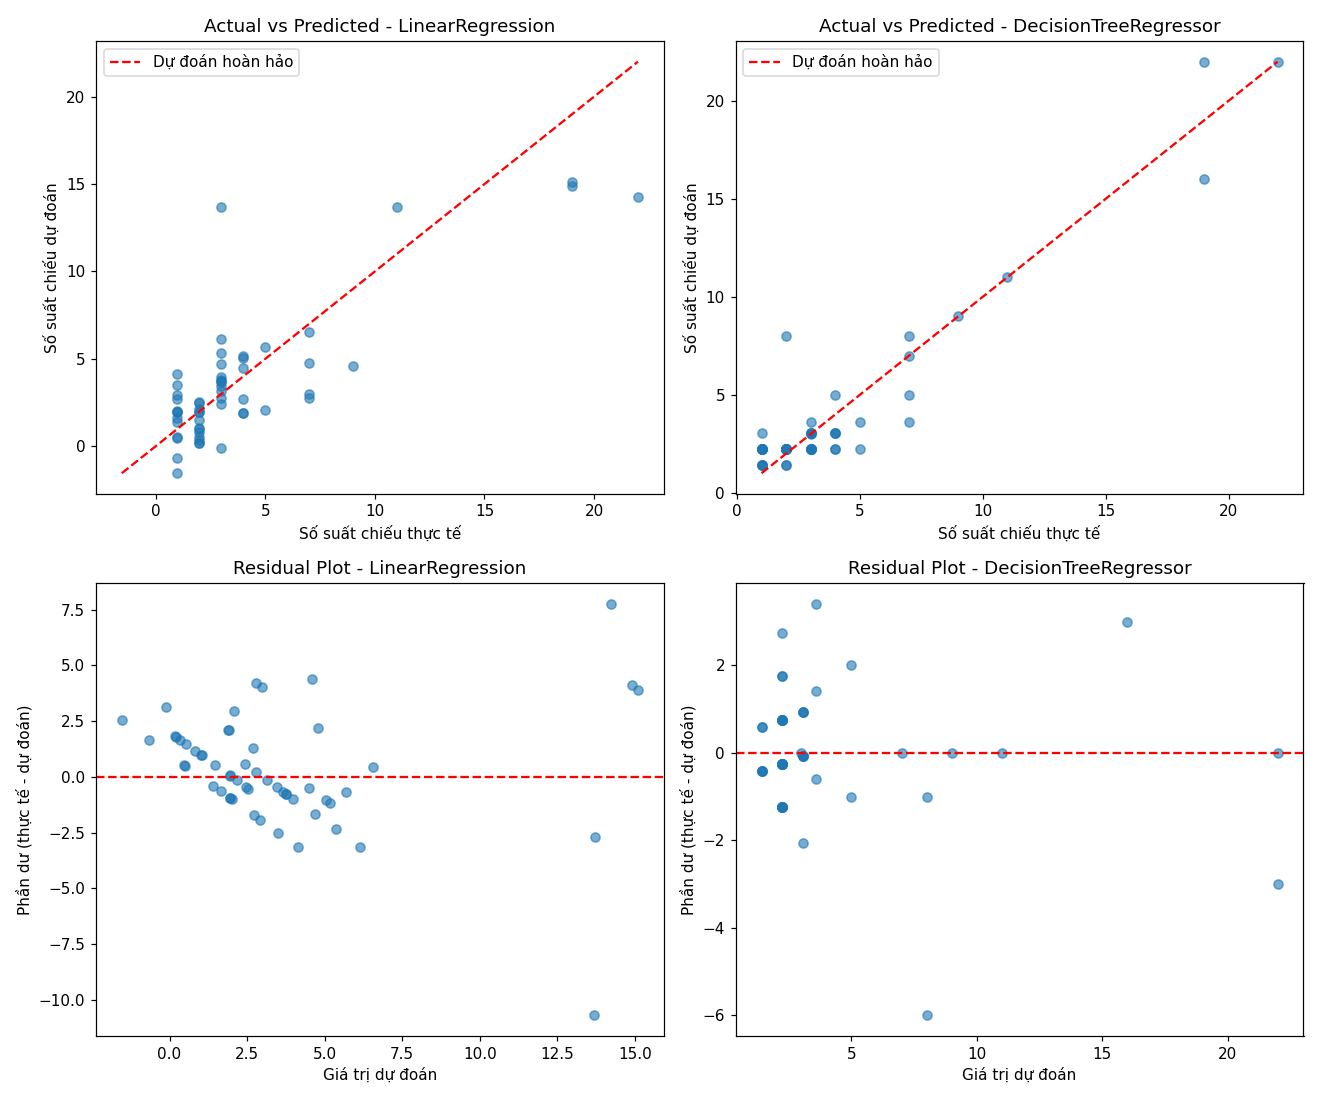

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, (name, p) in enumerate(preds.items()):
    ax = axes[0, i]
    ax.scatter(y_test, p, alpha=0.6)
    lims = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
    ax.plot(lims, lims, "r--", label="Dự đoán hoàn hảo")
    ax.set_xlabel("Số suất chiếu thực tế"); ax.set_ylabel("Số suất chiếu dự đoán")
    ax.set_title(f"Actual vs Predicted - {name}"); ax.legend()

    ax = axes[1, i]
    ax.scatter(p, y_test - p, alpha=0.6)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_xlabel("Giá trị dự đoán"); ax.set_ylabel("Phần dư (thực tế - dự đoán)")
    ax.set_title(f"Residual Plot - {name}")
plt.tight_layout()
plt.show()

## 5. Nhận xét
- Cây quyết định cho kết quả tốt hơn rõ rệt so với hồi quy tuyến tính (R² test khoảng 0.89 so với 0.65; RMSE test khoảng 1.42 so với 2.60). Số suất chiếu phụ thuộc phi tuyến vào phim và rạp: một số ít phim ở rạp lớn có 19-22 suất, còn đa số chỉ 1-4 suất.
- Cây có overfit nhẹ (R² train 0.96, test 0.89) nhưng khoảng cách vẫn chấp nhận được.
- Hồi quy tuyến tính dự đoán lệch xa ở các điểm có số suất cao, có dự đoán âm (không hợp lý với số suất chiếu) và có vài phần dư lớn, cho thấy lỗi mang tính hệ thống do mô hình không bắt được quan hệ phi tuyến.
- Phần dư của cây tập trung quanh 0 và có dạng bậc thang vì cây dự đoán cùng một giá trị cho mỗi nhóm lá.
- Hạn chế: chỉ có 280 mẫu, tập test 56 mẫu nên kết quả có thể thay đổi khi đổi `random_state`.